# Exercise 1 (10 points)

In this exercise, we will practice refactoring concepts in analytics/data science tasks. Consider the following scenario. You're given a dataset of employee information, and you need to transform it to prepare for analysis. The initial function, `transform_employee_data`, does this by:

- Converting salary values to floats.
- Standardizing department names to lowercase.
- Adding a new column called `salary_level` based on salary thresholds.

However, the function is not well-structured or efficient. Your task is to refactor it to improve its design. Here’s the initial, unrefactored code:

```
import pandas as pd

def transform_employee_data(df):
    # Convert salary to float
    for i in range(len(df)):
        df.loc[i, 'salary'] = float(df.loc[i, 'salary'])

    # Standardize department names
    for i in range(len(df)):
        df.loc[i, 'department'] = df.loc[i, 'department'].lower()

    # Add salary level column
    for i in range(len(df)):
        salary = df.loc[i, 'salary']
        if salary < 50000:
            df.loc[i, 'salary_level'] = 'low'
        elif 50000 <= salary < 100000:
            df.loc[i, 'salary_level'] = 'medium'
        else:
            df.loc[i, 'salary_level'] = 'high'

    return df

```

Refactoring instructions:

- **Remove loops**: The function uses loops which can be slow with large datasets. Use `pandas` vectorized operations to improve performance.
- **Simplify conditional**: Replace conditional logic with `pd.cut` for better readability.
- **Rename the function**: Use a more descriptive name.

Then, apply the refactored function to following data:

```
data = {'employee_id': [1, 2, 3],
        'salary': ['48000', '75000', '120000'],
        'department': ['Sales', 'Engineering', 'Marketing']
}
```

The expected outcome is shown below.

| employee_id | salary | department | salary_level |
| --- | --- | --- | --- |
| 1 | 48000.0 | sales | low |
| 2 | 75000.0 | engineering | medium |
| 3 | 120000.0 | marketing | high |



In [1]:
import pandas as pd

# Salary thresholds as named constants instead of magic numbers
LOW_SALARY_LIMIT = 50000
HIGH_SALARY_LIMIT = 100000


def prepare_employee_data_for_analysis(df: pd.DataFrame) -> pd.DataFrame:
    """Convert salary to float, lowercase department names, and add a salary_level column."""
    df = df.copy()  # leave the original DataFrame unchanged

    # Convert salary to float (vectorized, no loop)
    df['salary'] = df['salary'].astype(float)

    # Standardize department names to lowercase (vectorized, no loop)
    df['department'] = df['department'].str.lower()

    # Assign salary level with pd.cut instead of if/elif/else
    df['salary_level'] = pd.cut(
        df['salary'],
        bins=[float('-inf'), LOW_SALARY_LIMIT, HIGH_SALARY_LIMIT, float('inf')],
        labels=['low', 'medium', 'high'],
        right=False  # bins are [low, high), so 50000 is 'medium' and 100000 is 'high', same as the original
    )

    return df


# Apply the refactored function to the sample data
data = {'employee_id': [1, 2, 3],
        'salary': ['48000', '75000', '120000'],
        'department': ['Sales', 'Engineering', 'Marketing']
}

employee_df = pd.DataFrame(data)
prepared_df = prepare_employee_data_for_analysis(employee_df)
prepared_df

,employee_id,salary,department,salary_level
0,1,48000.0,sales,low
1,2,75000.0,engineering,medium
2,3,120000.0,marketing,high


# Exercise 2

In this exercise, we will practice `polars` operations.

### Exercise 2(a) (2 points)

Load `polars`, `matplotlib.pyplot` and `seaborn`.

In [2]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `diamond.csv` data file and create a data frame called `df`. Report the shape of `df`.

In [6]:
df = pl.read_csv("diamond.csv")
print(df.head())

shape: (5, 8)
┌──────────────┬───────┬───────┬─────────┬────────┬──────────┬────────┬───────┐
│ Carat Weight ┆ Cut   ┆ Color ┆ Clarity ┆ Polish ┆ Symmetry ┆ Report ┆ Price │
│ ---          ┆ ---   ┆ ---   ┆ ---     ┆ ---    ┆ ---      ┆ ---    ┆ ---   │
│ f64          ┆ str   ┆ str   ┆ str     ┆ str    ┆ str      ┆ str    ┆ i64   │
╞══════════════╪═══════╪═══════╪═════════╪════════╪══════════╪════════╪═══════╡
│ 1.1          ┆ Ideal ┆ H     ┆ SI1     ┆ VG     ┆ EX       ┆ GIA    ┆ 5169  │
│ 0.83         ┆ Ideal ┆ H     ┆ VS1     ┆ ID     ┆ ID       ┆ AGSL   ┆ 3470  │
│ 0.85         ┆ Ideal ┆ H     ┆ SI1     ┆ EX     ┆ EX       ┆ GIA    ┆ 3183  │
│ 0.91         ┆ Ideal ┆ E     ┆ SI1     ┆ VG     ┆ VG       ┆ GIA    ┆ 4370  │
│ 0.83         ┆ Ideal ┆ G     ┆ SI1     ┆ EX     ┆ EX       ┆ GIA    ┆ 3171  │
└──────────────┴───────┴───────┴─────────┴────────┴──────────┴────────┴───────┘


### Exercise 2(c) (3 points)

Create the frequency table of `Cut`.

In [10]:
# Frequency table of Cut, sorted from most to least common
df['Cut'].value_counts(normalize=True)

Cut,proportion
str,f64
"""Very Good""",0.404667
"""Ideal""",0.413667
"""Signature-Ideal""",0.042167
"""Fair""",0.0215
"""Good""",0.118


### Exercise 2(d) (3 points)

Report the average `Price` based on `Color`.

In [ ]:
# Average Price for each Color
df.group_by('Color').agg(pl.col('Price').mean().alias('avg_price')).sort('Color')


Color,avg_price
str,f64
"""D""",15255.783661
"""E""",11539.190231
"""F""",12712.241856
"""G""",12520.050633
"""H""",10487.347544
"""I""",8989.636364


### Exercise 2(e) (3 points)

Report the average `Price` based on `Cut` and `Color`.

In [12]:
# Average Price for each Cut and Color
df.group_by('Cut','Color').agg(pl.col('Price').mean().alias('avg_price')).sort('Color')

Cut,Color,avg_price
str,str,f64
"""Very Good""","""D""",13218.826415
"""Ideal""","""D""",18461.953571
"""Signature-Ideal""","""D""",19823.1
"""Fair""","""D""",6058.25
"""Good""","""D""",10058.716216
…,…,…
"""Good""","""I""",8174.113043
"""Very Good""","""I""",8930.031332
"""Ideal""","""I""",9459.588378


### Exercise 2(f) (3 points)

Compute the correlation between `Carat Weight` and `Price`. 

In [14]:
#df[['Carat Weight', 'Price']].corr

# Pearson correlation between Carat Weight and Price
df.select(pl.corr('Carat Weight', 'Price').alias('corr_carat_price'))

corr_carat_price
f64
0.858562


### Exercise 2(g) (4 points)

Create a scatter plot between `Carat Weight` and `Price`.

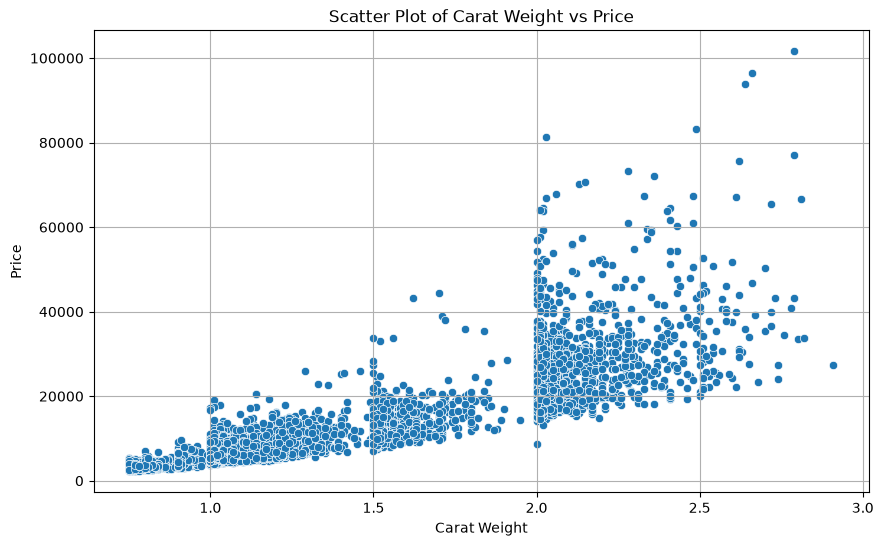

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))

# Convert to pandas without pyarrow: polars -> dict of lists -> pandas
plot_df = pd.DataFrame(df.select(["Carat Weight", "Price"]).to_dict(as_series=False))

sns.scatterplot(data=plot_df, x="Carat Weight", y="Price", ax=ax)
ax.set_title("Scatter Plot of Carat Weight vs Price")
ax.set_xlabel("Carat Weight")
ax.set_ylabel("Price")
ax.grid(True)
plt.show();

# Exercise 3 (5 points)

In this exercise, we will discuss design and refactoring concepts in applied data science.

Explain what the *single responsibility principle* means for a data science workflow, and why splitting a long, monolithic analysis script into small, focused functions (e.g., loading, cleaning, feature engineering, modeling) makes the code easier to test, reuse, and maintain. In your answer, also explain why refactoring should preserve the code's behavior, and how you would verify that a refactored function still produces the same results as the original.

### Single Responsibility Principle

The **single responsibility principle** means each function should do one job. In a data science workflow, that means separate functions for loading, cleaning, feature engineering, and modeling. If a function's name needs "and," it is doing too much.

Small, focused functions are:
- **Easier to test:** each one can be checked with a small sample of data.
- **Easier to reuse:** a function can be imported into other projects instead of copied.
- **Easier to maintain:** when something changes, I know exactly which function to update.

### Preserving Behavior

Refactoring changes how the code is structured, not what it produces. If the output changes, other code and reports that depend on it could break without anyone noticing.

To verify a refactor, I run the original and refactored functions on the same data and compare the results (for example with `pd.testing.assert_frame_equal`), check edge cases like boundary values, and re-run unit tests after each change.